Install Dependencies

In [314]:
%pip install tensorflow tensorboard opencv-python matplotlib

Note: you may need to restart the kernel to use updated packages.


In [315]:
%pip list

Package                  Version
------------------------ ----------
absl-py                  2.5.1
aiohappyeyeballs         2.7.1
aiohttp                  3.14.5
aiosignal                1.4.0
annotated-doc            0.0.5
annotated-types          0.8.0
anyio                    4.15.1
appnope                  1.0.0
asttokens                3.0.2
astunparse               1.6.3
attrs                    26.1.0
certifi                  2026.10.23
cffi                     2.1.1
charset-normalizer       3.5.2
click                    8.5.0
cloudpickle              3.1.2
comm                     0.2.3
contourpy                1.4.0
cryptography             50.0.2
cycler                   0.12.1
datasets                 5.1.0
debugpy                  1.8.22
dill                     0.4.1
executing                2.3.0
fastapi                  0.161.1
filelock                 4.2.4
flatbuffers              25.12.19
fonttools                4.67.0
frozenlist               1.8.0
fsspec         

In [316]:
import tensorflow as tf
import os

In [317]:
gpus = tf.config.experimental.list_physical_devices('CPU')

In [318]:
gpus

[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]

In [319]:
# Avoid OOM errors by setting GPU memory consumption 
gpus = tf.config.experimental.list_physical_devices('GPU')

for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

Remove Dodgy Images

In [320]:
import cv2
import imghdr

In [321]:
data_dir = 'data' # Specify the path to your dataset directory


In [322]:
image_exts = ['jpeg', 'jpg', 'bmp', 'png']

In [323]:
image_exts[2]

'bmp'

In [324]:
for image_class in os.listdir(data_dir):
        image_path = os.path.join(data_dir, image_class)

        if not os.path.isdir(image_path) or image_class.startswith('.'):
            continue

        for image in os.listdir(image_path):
            if image.startswith('.'):
                continue

            file_path = os.path.join(image_path, image)
        try:
            img = cv2.imread(file_path)
            tip = imghdr.what(file_path)
            if tip not in image_exts:
                print('Image not in ext list {}'.format(file_path))
                os.remove(file_path)
        except Exception as e:
            print('Issue with image {}'.format(file_path))

In [325]:
tf.data.Dataset??

Init signature: tf.data.Dataset(variant_tensor)
Source:        
@tf_export("data.Dataset", v1=[])
class DatasetV2(
    collections_abc.Iterable,
    tracking_base.Trackable,
    composite_tensor.CompositeTensor,
    data_types.DatasetV2,
    metaclass=abc.ABCMeta):
  """Represents a potentially large set of elements.

  The `tf.data.Dataset` API supports writing descriptive and efficient input
  pipelines. `Dataset` usage follows a common pattern:

  1. Create a source dataset from your input data.
  2. Apply dataset transformations to preprocess the data.
  3. Iterate over the dataset and process the elements.

  Iteration happens in a streaming fashion, so the full dataset does not need to
  fit into memory.

  Source Datasets:

  The simplest way to create a dataset is to create it from a python `list`:

  >>> dataset = tf.data.Dataset.from_tensor_slices([1, 2, 3])
  >>> for element in dataset:
  ...   print(element)
  tf.Tensor(1, shape=(), dtype=int32)
  tf.Tensor(2, shape=(), dty

In [326]:
import numpy as np
from matplotlib import pyplot as plt

In [327]:
# Load once with a fixed seed. Shuffle membership is frozen later before the split
# so train/val/test do not reshuffle into each other across epochs (data leakage).
data = tf.keras.utils.image_dataset_from_directory(
    'data',
    shuffle=True,
    seed=42,
    image_size=(256, 256),
    batch_size=32,
)

Found 10606 files belonging to 2 classes.


In [328]:
data_iterator = data.as_numpy_iterator()

In [329]:
batch = data_iterator.next()

In [330]:
# Image is represented as numpy array of shape (batch_size, height, width, channels)
batch[0].shape 

(32, 256, 256, 3)

In [331]:
# Class 1 = Dogs, Class 0 = Cats
batch[1]

array([1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1,
       1, 1, 1, 0, 1, 0, 1, 0, 1, 1], dtype=int32)

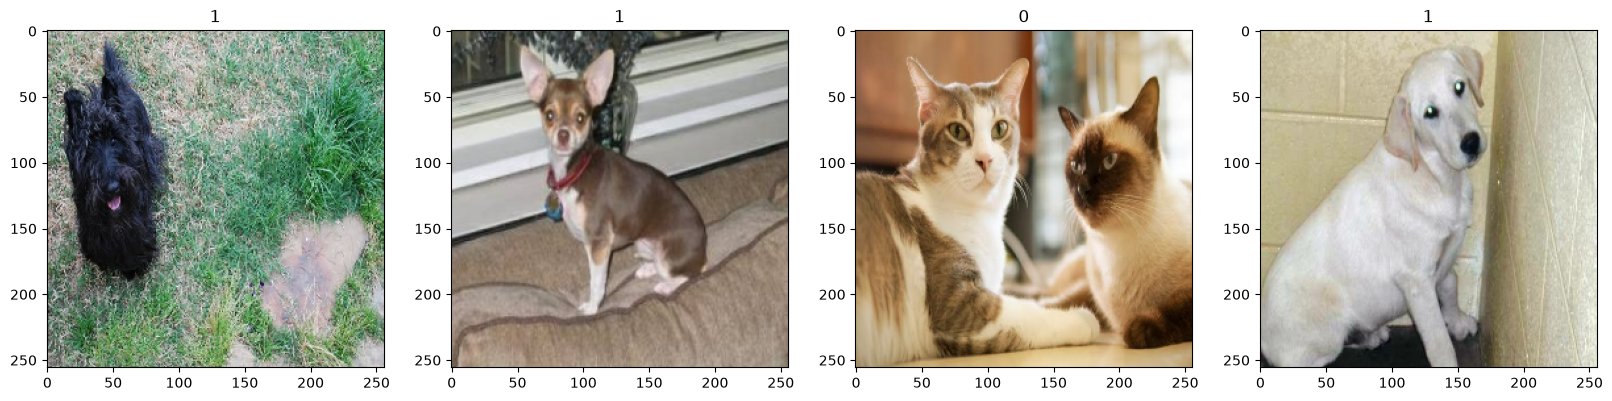

In [332]:
# We learn that here are 4 images in the batch, that allow us to figure out the binary class we specified in the above cell.
fig, ax = plt.subplots(ncols=4, figsize=(20,20))
for idx, img in enumerate(batch[0][:4]):
    ax[idx].imshow(img.astype(int))
    ax[idx].title.set_text(batch[1][idx])

In [333]:
# Re-create the dataset with a fixed seed (same as above) after exploratory batch peeks
data = tf.keras.utils.image_dataset_from_directory(
    'data',
    shuffle=True,
    seed=42,
    image_size=(256, 256),
    batch_size=32,
)

Found 10606 files belonging to 2 classes.


In [334]:
# Find the minimum pixel values in the batch of images
batch[0].min()


np.float32(0.0)

In [335]:
# Find the maximum pixel values in the batch of images to understand the range of pixel values in the images for lambda function preprocessing
batch[0].max()

np.float32(255.0)

In [336]:
# Use lambda functions for batch preprocessing, such as normalization and resizing
data = data.map(lambda x, y: (x/255, y))

In [337]:
scaled_iterator = data.as_numpy_iterator()

In [338]:
batch = scaled_iterator.next()

In [339]:
batch[0].min()

np.float32(0.0)

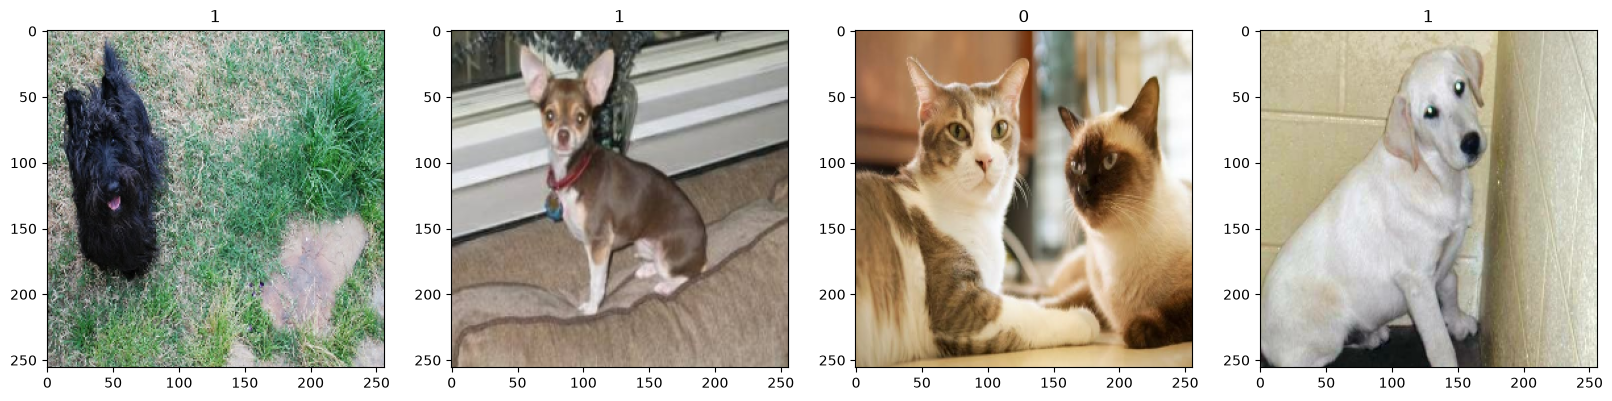

In [340]:
fig, ax = plt.subplots(ncols=4, figsize=(20, 20))
for idx, img in enumerate(batch[0][:4]):
    ax[idx].imshow(img)
    ax[idx].title.set_text(batch[1][idx])

In [341]:
len(data)

332

In [342]:
# Freeze shuffle so take/skip always select the same batches (prevents train/val/test leakage).
data = data.shuffle(buffer_size=5000, seed=42, reshuffle_each_iteration=False)

# 70% train / 20% val / 10% test — sizes must sum exactly to len(data)
n = len(data)
train_size = int(n * 0.7)
val_size = int(n * 0.2)
test_size = n - train_size - val_size
print(f'batches: total={n}, train={train_size}, val={val_size}, test={test_size}')

batches: total=332, train=232, val=66, test=34


In [343]:
train = data.take(train_size).shuffle(1000)  # reshuffle training only across epochs
val = data.skip(train_size).take(val_size)
test = data.skip(train_size + val_size).take(test_size)

# Augment train only — never apply to val/test (that would distort the real metric)
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
])

train = train.map(
    lambda x, y: (data_augmentation(x, training=True), y),
    num_parallel_calls=tf.data.AUTOTUNE,
)
train = train.prefetch(tf.data.AUTOTUNE)
val = val.prefetch(tf.data.AUTOTUNE)
test = test.prefetch(tf.data.AUTOTUNE)

In [344]:
len(test)

34

Build Deep Learning Model

In [345]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Dropout

In [346]:
model = Sequential()


In [347]:
MaxPooling2D??

Init signature:
MaxPooling2D(
    pool_size=(2, 2),
    strides=None,
    padding='valid',
    data_format=None,
    name=None,
    **kwargs,
)
Source:        
@keras_export(["keras.layers.MaxPooling2D", "keras.layers.MaxPool2D"])
class MaxPooling2D(BasePooling):
    """Max pooling operation for 2D spatial data.

    Downsamples the input along its spatial dimensions (height and width)
    by taking the maximum value over an input window
    (of size defined by `pool_size`) for each channel of the input.
    The window is shifted by `strides` along each dimension.

    The resulting output when using the `"valid"` padding option has a spatial
    shape (number of rows or columns) of:
    `output_shape = math.floor((input_shape - pool_size) / strides) + 1`
    (when `input_shape >= pool_size`)

    The resulting output shape when using the `"same"` padding option is:
    `output_shape = math.floor((input_shape - 1) / strides) + 1`

    Args:
        pool_size: int or tuple of 2 integers

In [348]:
# Conv2D(# filters, size of filter, stride, activation function, input shape)
model.add(Conv2D(16, (3,3), 1, activation='relu', input_shape=(256, 256, 3)))
model.add(MaxPooling2D())

model.add(Conv2D(32, (3,3), 1, activation='relu'))
model.add(MaxPooling2D())

model.add(Conv2D(16, (3,3), 1, activation='relu'))
model.add(MaxPooling2D())

model.add(Flatten())

# Smaller dense + dropout to reduce memorization
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(1, activation='sigmoid'))



In [349]:
model.compile('adam', loss=tf.losses.BinaryCrossentropy(), metrics=['accuracy'])

In [350]:
model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 254, 254, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 127, 127, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 125, 125, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 62, 62, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 60, 60, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 30, 30, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 14400)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │     1,843,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,853,169 (7.07 MB)

 Trainable params: 1,853,169 (7.07 MB)

 Non-trainable params: 0 (0.00 B)

ReLU (Rectified Linear Unit) is an activation function in artificial neural networks.

Formula & Behavior

• Mathematical Definition: (f(x) = max(0, x))
• Output: It passes positive values directly through unchanged (f(x) = x) and outputs 0 for any negative input (f(x) = 0).

The sigmoid function (specifically the logistic function) is a mathematical S-shaped curve that maps any real-valued number into a constrained range between 0 and 1

Train The Model

In [351]:
logdir = 'logs'

In [352]:
# TensorBoard logging + early stopping (halt when val_loss stops improving)
tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=logdir)
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
)

In [353]:
hist = model.fit(
    train,
    epochs=40,
    validation_data=val,
    callbacks=[tensorboard_callback, early_stopping],
)

Epoch 1/40


W0000 00:00:1793728099.759567 10054719 png_io.cc:96] PNG warning: iCCP: known incorrect sRGB profile


232/232 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.6235 - loss: 0.6519

W0000 00:00:1793728121.664486 10055696 png_io.cc:96] PNG warning: iCCP: known incorrect sRGB profile


232/232 ━━━━━━━━━━━━━━━━━━━━ 28s 102ms/step - accuracy: 0.6235 - loss: 0.6519 - val_accuracy: 0.6544 - val_loss: 0.6089
Epoch 2/40


W0000 00:00:1793728125.752311 10056053 png_io.cc:96] PNG warning: iCCP: known incorrect sRGB profile


... (143 outputs left out)

W0000 00:00:1793729104.036023 10081793 png_io.cc:96] PNG warning: iCCP: known incorrect sRGB profile


232/232 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.8535 - loss: 0.3384

W0000 00:00:1793729129.516212 10082660 png_io.cc:96] PNG warning: iCCP: known incorrect sRGB profile


232/232 ━━━━━━━━━━━━━━━━━━━━ 29s 118ms/step - accuracy: 0.8535 - loss: 0.3384 - val_accuracy: 0.8267 - val_loss: 0.3994


In [354]:
hist.history

{'accuracy': [0.6235484480857849,
  0.6596003174781799,
  0.68133944272995,
  0.7006481289863586,
  0.7111801505088806,
  0.724952757358551,
  0.7356197834014893,
  0.7564136981964111,
  0.7622198462486267,
  0.7637050747871399,
  0.7777477502822876,
  0.7759924530982971,
  0.7846340537071228,
  0.7884147763252258,
  0.793005645275116,
  0.7959762215614319,
  0.8035376667976379,
  0.8086686730384827,
  0.8063732385635376,
  0.8133945465087891,
  0.8135295510292053,
  0.8179854154586792,
  0.8214960694313049,
  0.8309478759765625,
  0.8301377296447754,
  0.8324331641197205,
  0.8308128714561462,
  0.8344585299491882,
  0.8347285985946655,
  0.8416149020195007,
  0.8408047556877136,
  0.8382392525672913,
  0.8451255559921265,
  0.8476910591125488,
  0.8479611277580261,
  0.8447204828262329,
  0.8557925820350647,
  0.8534971475601196],
 'loss': [0.6518911123275757,
  0.613933265209198,
  0.5935659408569336,
  0.5801463723182678,
  0.5637872219085693,
  0.5502546429634094,
  0.528272688388

Plot the Model Performance

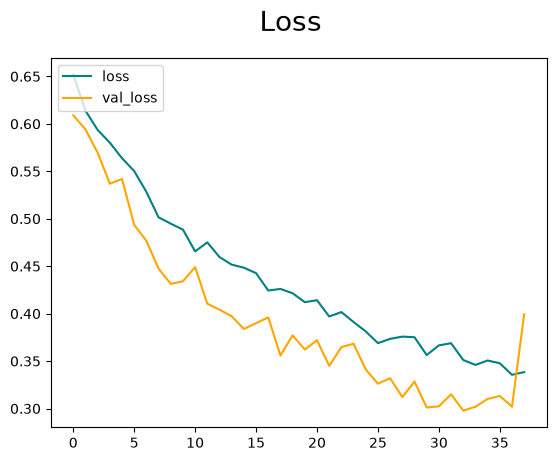

In [355]:
fig = plt.figure()
plt.plot(hist.history['loss'], color='teal', label='loss')
plt.plot(hist.history['val_loss'], color='orange', label='val_loss')
fig.suptitle('Loss', fontsize=20)
plt.legend(loc='upper left')
plt.show()


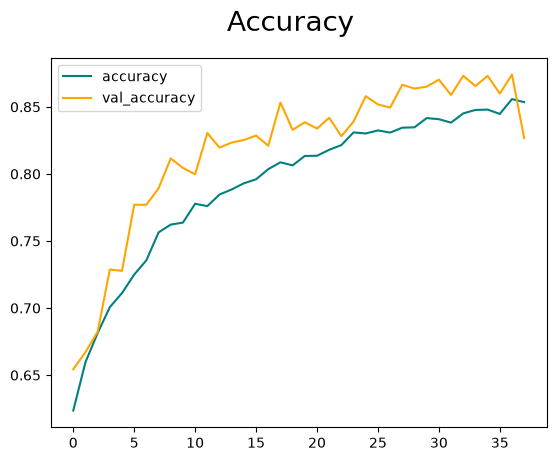

In [356]:
fig = plt.figure()
plt.plot(hist.history['accuracy'], color='teal', label='accuracy')
plt.plot(hist.history['val_accuracy'], color='orange', label='val_accuracy')
fig.suptitle('Accuracy', fontsize=20)
plt.legend(loc='upper left')
plt.show()

Evaluating the Model Performance

In [357]:
from tensorflow.keras.metrics import Precision, Recall, BinaryAccuracy

In [358]:
precision = Precision()
recall = Recall()
accuracy = BinaryAccuracy()

In [359]:
len(test)

34

In [360]:
for batch in test.as_numpy_iterator():
    X, y = batch
    yhat = model.predict(X)
    precision.update_state(y, yhat)
    recall.update_state(y, yhat)
    accuracy.update_state(y, yhat)

W0000 00:00:1793729133.859685 10082788 png_io.cc:96] PNG warning: iCCP: known incorrect sRGB profile


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━

In [361]:
print(f'Precision: {precision.result().numpy()}, Recall: {recall.result().numpy()}, Accuracy: {accuracy.result().numpy()}')

Precision: 0.868852436542511, Recall: 0.9464285969734192, Accuracy: 0.8786764740943909


Test the Model

In [362]:
import cv2

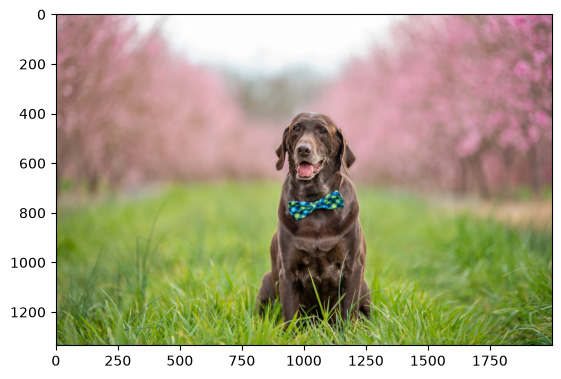

In [363]:
img = cv2.imread('dog_test.jpg')
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.show()

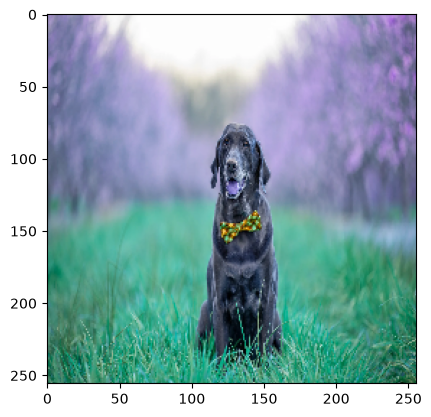

In [364]:
resize = tf.image.resize(img, (256, 256))
plt.imshow(resize.numpy().astype(int))
plt.show()

In [365]:
resize.shape

TensorShape([256, 256, 3])

In [366]:
np.expand_dims(resize, 0).shape

(1, 256, 256, 3)

In [367]:
# Our NN expects a batch, so we encapsulate the image in a batch of size 1. We also normalize the pixel values to be between 0 and 1 by dividing by 255.
yhat = model.predict(np.expand_dims(resize/255, 0))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


In [368]:
# Our yhat is a probability value close to 1, indicating an accurate dog prediction
yhat

array([[0.90460914]], dtype=float32)

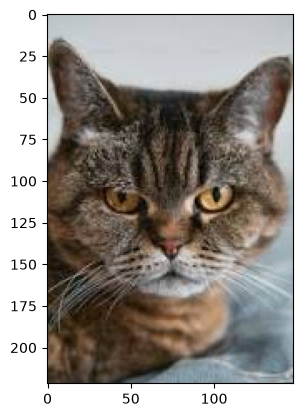

In [369]:
# Lets do it for the cat image as well
img = cv2.imread('cat_test.jpg')
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.show()

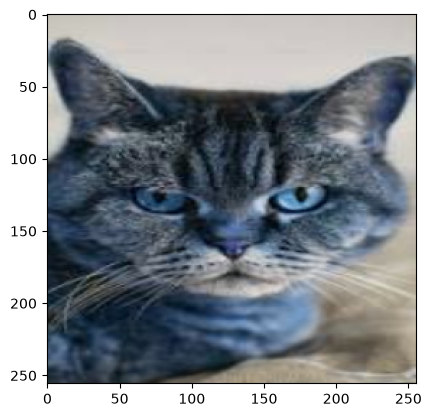

In [370]:
resize = tf.image.resize(img, (256, 256))
plt.imshow(resize.numpy().astype(int))
plt.show()

In [371]:
resize.shape

TensorShape([256, 256, 3])

In [372]:
np.expand_dims(resize, 0).shape

(1, 256, 256, 3)

In [373]:
yhat = model.predict(np.expand_dims(resize/255, 0))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


In [374]:
yhat

array([[0.01848972]], dtype=float32)

Save the model for future use

In [375]:
from tensorflow.keras.models import load_model

In [376]:
model.save(os.path.join('models', 'image_classifier.h5'))

Reload the Model As New

In [377]:
new_model = load_model(os.path.join('models', 'image_classifier.h5'))

In [378]:
# Run the new model
yhatNew = new_model.predict(np.expand_dims(resize/255, 0))

if yhatNew > 0.5:
    print('Predicted class: Dog')
else:
    print('Predicted class: Cat')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
Predicted class: Cat


## Evaluate on holdout (true generalization check)

`holdout/` images were never in `data/`, so they were not used in train/val/test. If accuracy here is much lower than the in-pipeline 100%, the model overfit the training split.

In [379]:
# Load the saved model (use the filename you actually saved)
holdout_model = load_model(os.path.join('models', 'image_classifier.h5'))

# image_dataset_from_directory labels folders alphabetically: cats=0, dogs=1
holdout_ds = tf.keras.utils.image_dataset_from_directory(
    'holdout',
    shuffle=False,
    image_size=(256, 256),
    batch_size=32,
)
holdout_ds = holdout_ds.map(lambda x, y: (x / 255.0, y))

holdout_precision = Precision()
holdout_recall = Recall()
holdout_accuracy = BinaryAccuracy()

for batch in holdout_ds.as_numpy_iterator():
    X, y = batch
    yhat = holdout_model.predict(X, verbose=0)
    holdout_precision.update_state(y, yhat)
    holdout_recall.update_state(y, yhat)
    holdout_accuracy.update_state(y, yhat)

print(
    f'Holdout Precision: {holdout_precision.result().numpy():.4f}, '
    f'Recall: {holdout_recall.result().numpy():.4f}, '
    f'Accuracy: {holdout_accuracy.result().numpy():.4f}'
)

Found 100 files belonging to 2 classes.
Holdout Precision: 0.7931, Recall: 0.9200, Accuracy: 0.8400
